# Василеостровский район: учебное исследование в BlocksNet

**Цель** — собрать информацию о кварталах Василеостровского района и рассчитать
показатели, которые разбираются в `examples/pipeline.ipynb` библиотеки BlocksNet.

**Территория** — Василеостровский район Санкт-Петербурга.
**Единица анализа** — городской квартал.

**Что будет в результате:**

- границы района и исходные слои OpenStreetMap;
- кварталы и назначенное землепользование;
- пешеходный граф и матрица времени в пути между кварталами;
- здания, население, школы и их ёмкость;
- плотностные показатели, морфотипы, обеспеченность школами, доступность;
- итоговая таблица и GeoJSON для будущего дашборда.

**Источники данных:** OpenStreetMap (© участники OpenStreetMap, лицензия ODbL).
**Граф:** пешеходная сеть OpenStreetMap, скорость 5 км/ч, время в минутах.
**Версия BlocksNet:** 1.0.0a9.

> **Как запускать.** Выполняйте ячейки сверху вниз. В ноутбуке есть
> **обязательная остановка** после подготовки кварталов: перед расчётами
> нужно согласовать список метрик. Не запускайте всё сразу через
> «Run All», пока не пройдёте остановку.

## 0. Устройство ноутбука

1. Настройка окружения и папок.
2. Граница района.
3. Исходные слои OpenStreetMap.
4. Нарезка кварталов и землепользование.
5. **Справочник метрик** — что умеет BlocksNet и что считаем мы.
6. **ОСТАНОВКА** — согласование метрик.
7. Пешеходный граф и матрица времени.
8. Здания и население.
9. Школы и ёмкость.
10. Показатели: плотность, морфотипы, обеспеченность, доступность.
11. Сохранение итогов.
12. Проверка результатов.
13. Паспорт запуска и инструкция повторного запуска.
14. Что будет на следующем этапе.

Все скачанные данные и результаты сохраняются в `data/vasileostrovsky/`.
При повторном запуске готовые файлы читаются с диска, а не скачиваются заново.

## 1. Настройка окружения

Сначала импортируем библиотеки и посмотрим версии. Это важно: ноутбук написан
под BlocksNet **1.0.0a9**. В других версиях часть функций может называться иначе.

In [1]:
import json
import math
import numbers
import time
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd

import blocksnet
import iduedu as ie

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)

print("BlocksNet:", blocksnet.__version__)
print("OSMnx:", ox.__version__)
print("IduEdu:", ie.__version__)
print("GeoPandas:", gpd.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

BlocksNet: 1.0.0a9
OSMnx: 2.1.1
IduEdu: 0.4.1
GeoPandas: 1.2.0
Pandas: 2.3.3
NumPy: 2.2.6


### 1.1. Параметры исследования

`FORCE_REDOWNLOAD = False` означает «использовать готовые файлы».
Поставьте `True`, если нужно заново скачать данные из OpenStreetMap.

In [2]:
TERRITORY_NAME = "Василеостровский район, Санкт-Петербург, Россия"

WALK_SPEED_KMH = 5.0
WALK_SPEED_M_PER_MIN = WALK_SPEED_KMH * 1000 / 60
GRAPH_BUFFER_M = 500
RANDOM_STATE = 42

# Overpass иногда отвечает медленно. Ноутбук сам пробует несколько зеркал.
OVERPASS_ENDPOINTS = (
    "https://overpass-api.de/api",
    "https://overpass.kumi.systems/api",
    "https://overpass.private.coffee/api",
)
OVERPASS_TIMEOUT = 300
OVERPASS_MAX_AREA = 5_000_000  # 5 км² на один запрос: меньше риск таймаута

USE_CACHE = True
FORCE_REDOWNLOAD = False

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "vasileostrovsky"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"
GRAPH_PATH = PROCESSED_DIR / "walk_graph.graphml"

for folder in (RAW_DIR, PROCESSED_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

ox.settings.requests_timeout = OVERPASS_TIMEOUT
ox.settings.max_query_area_size = OVERPASS_MAX_AREA

print("Папка проекта:", PROJECT_DIR)
print("Данные:", DATA_DIR)
print("Скорость ходьбы:", WALK_SPEED_KMH, "км/ч")
print("Таймаут Overpass:", OVERPASS_TIMEOUT, "сек")

Папка проекта: /Users/polina/python-package-boilerplate/notebooks/cache
Данные: /Users/polina/python-package-boilerplate/notebooks/cache/data/vasileostrovsky
Скорость ходьбы: 5.0 км/ч
Таймаут Overpass: 300 сек


### 1.2. Вспомогательные функции

Функции ниже нужны, чтобы:

- сохранять слои в GeoJSON в системе координат WGS84 (так требуют GeoJSON и веб-карты);
- читать GeoJSON и перепроектировать его в локальную метрическую систему;
- переиспользовать готовые файлы;
- корректно сохранять и загружать граф.

Никаких расчётов эти функции не выполняют.

In [3]:
def _first(value):
    """Берёт первое значение, если OSM вернул список."""
    if isinstance(value, (list, tuple)):
        return value[0] if value else None
    return value


def _json_safe(value):
    """Приводит значение к виду, который понимает GeoJSON."""
    if value is None or value is pd.NA:
        return None
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, (str, bool)):
        return value
    if isinstance(value, numbers.Integral):
        return int(value)
    if isinstance(value, numbers.Real):
        number = float(value)
        return None if not math.isfinite(number) else number
    if isinstance(value, (list, tuple, dict)):
        return json.dumps(value, ensure_ascii=False)
    if hasattr(value, "value"):
        return value.value
    return str(value)


def write_geojson(gdf, path):
    """Сохраняет GeoDataFrame в GeoJSON (WGS84)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    out = gdf.copy()

    if out.crs is None:
        out = out.set_crs(4326)
    elif out.crs.to_epsg() != 4326:
        out = out.to_crs(4326)

    geometry_name = out.geometry.name
    for column in out.columns:
        if column == geometry_name:
            continue
        if pd.api.types.is_datetime64_any_dtype(out[column]):
            out[column] = out[column].astype(str)
        elif out[column].dtype == object:
            out[column] = out[column].map(_json_safe)

    out.to_file(path, driver="GeoJSON")
    print(f"Сохранено: {path.relative_to(PROJECT_DIR)} ({len(out)} объектов)")


def read_geojson(path, target_crs=None):
    """Читает GeoJSON и при необходимости перепроектирует."""
    gdf = gpd.read_file(path)
    if target_crs is not None:
        gdf = gdf.to_crs(target_crs)
    return gdf


def keep_columns(gdf, columns):
    """Оставляет нужные колонки, добавляя отсутствующие как пустые."""
    out = gdf.copy()
    for column in columns:
        if column not in out.columns:
            out[column] = None
    return out[columns + [out.geometry.name]].copy()


def normalize_column_names(gdf):
    """Убирает двоеточия из имён колонок OSM."""
    return gdf.rename(columns={column: str(column).replace(":", "_") for column in gdf.columns})


def download_osm_features(tags, label, attempts=3):
    """Скачивает слой OSM, переключая зеркала Overpass при таймауте."""
    last_error = None
    for attempt in range(1, attempts + 1):
        for endpoint in OVERPASS_ENDPOINTS:
            try:
                ox.settings.overpass_url = endpoint
                print(f"{label}: попытка {attempt}, сервер {endpoint} ...")
                return ox.features_from_polygon(boundaries_4326.union_all(), tags=tags)
            except Exception as exc:
                last_error = exc
                print(f"  не получилось: {type(exc).__name__}. Жду 5 секунд.")
                time.sleep(5)
    raise RuntimeError(
        f"Не удалось скачать слой «{label}» ни с одного зеркала Overpass. "
        "Подождите 5–10 минут и запустите эту ячейку снова: уже готовые слои сохранятся."
    ) from last_error


def load_osm_layer(filename, tags, columns, geometry_types, label):
    """Скачивает слой OSM один раз и дальше читает его из GeoJSON."""
    path = RAW_DIR / filename
    columns = [column.replace(":", "_") for column in columns]

    if USE_CACHE and not FORCE_REDOWNLOAD and path.exists():
        gdf = gpd.read_file(path)
        source = "из кэша"
    else:
        gdf = download_osm_features(tags, label)
        gdf = gdf.reset_index(drop=True)
        gdf = gdf[gdf.geom_type.isin(geometry_types)].copy()
        gdf = normalize_column_names(gdf)
        for column in columns:
            if column in gdf.columns:
                gdf[column] = gdf[column].map(_first)
        gdf = keep_columns(gdf, columns)
        if len(gdf) > 0:
            write_geojson(gdf, path)
        source = "из OSM"

    gdf = gdf.to_crs(crs)
    print(f"{label}: {len(gdf)} объектов ({source})")
    return gdf


def load_walk_graph(path):
    """Загружает GraphML и возвращает типы, которые ожидает BlocksNet."""
    graph = ox.load_graphml(
        path,
        node_dtypes={"x": float, "y": float},
        edge_dtypes={"length_meter": float, "time_min": float},
        graph_dtypes={"crs": int, "walk_speed": float},
    )
    graph.graph["type"] = "walk"
    return graph

### 1.3. Проверка версии

Если версия не совпадает, ноутбук остановится с понятным сообщением.

In [4]:
EXPECTED_BLOCKS_NET = "1.0.0a9"
if blocksnet.__version__ != EXPECTED_BLOCKS_NET:
    raise RuntimeError(
        f"Нужен BlocksNet {EXPECTED_BLOCKS_NET}, а установлен {blocksnet.__version__}. "
        "Выполните: pip install -e '.[research]'"
    )
print("Версия BlocksNet подходит.")

Версия BlocksNet подходит.


## 2. Граница района

Границу берём из OpenStreetMap через `osmnx.geocode_to_gdf`.
Если файл `raw/boundary.geojson` уже есть, он будет прочитан с диска.

Файл `raw/boundary.geojson` — это обычный GeoJSON с одним полигоном
и свойствами:

- `name_ru`, `name_en` — название района;
- `city_ru`, `country_ru` — город и страна;
- `area_km2` — площадь полигона в км² (вместе с водой);
- `center_lat`, `center_lon` — центральная точка;
- `bbox_*` — охватывающий прямоугольник;
- `source`, `source_method`, `source_license` — откуда данные.

Свойства нужны, чтобы файл можно было открыть в QGIS или на веб-карте
и сразу понять, что это за территория. Без них осталась бы только геометрия.

После чтения проверяем, что это полигон, и переводим его в локальную
метрическую проекцию UTM. В ней удобно считать площади и расстояния.

In [5]:
boundary_path = RAW_DIR / "boundary.geojson"

if USE_CACHE and not FORCE_REDOWNLOAD and boundary_path.exists():
    boundaries = read_geojson(boundary_path)
    print("Граница: из кэша")
else:
    boundaries = ox.geocode_to_gdf(TERRITORY_NAME)
    boundaries = boundaries[boundaries.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
    if len(boundaries) == 0:
        raise RuntimeError(
            "Не удалось получить полигон района. "
            "Проверьте название территории или используйте OSM relation id."
        )
    boundaries = boundaries.to_crs(4326)
    boundaries = gpd.GeoDataFrame(geometry=[boundaries.union_all()], crs=4326)
    boundaries["name_ru"] = "Василеостровский район"
    boundaries["name_en"] = "Vasileostrovsky District"
    boundaries["city_ru"] = "Санкт-Петербург"
    boundaries["country_ru"] = "Россия"
    boundaries["source"] = "OpenStreetMap"
    boundaries["source_method"] = "osmnx.geocode_to_gdf"
    boundaries["source_license"] = "ODbL 1.0 (© участники OpenStreetMap)"
    boundaries_tmp = boundaries.to_crs(boundaries.estimate_utm_crs())
    centroid = boundaries.geometry.iloc[0].centroid
    min_lon, min_lat, max_lon, max_lat = boundaries.total_bounds
    boundaries["area_km2"] = round(float(boundaries_tmp.area.sum() / 1e6), 2)
    boundaries["center_lat"] = float(centroid.y)
    boundaries["center_lon"] = float(centroid.x)
    boundaries["bbox_min_lat"] = float(min_lat)
    boundaries["bbox_min_lon"] = float(min_lon)
    boundaries["bbox_max_lat"] = float(max_lat)
    boundaries["bbox_max_lon"] = float(max_lon)
    write_geojson(boundaries, boundary_path)
    print("Граница: из OSM")

boundaries = boundaries.to_crs(4326)
boundaries = boundaries[boundaries.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
if len(boundaries) == 0:
    raise RuntimeError("Граница не является полигоном.")
if len(boundaries) > 1:
    boundaries = gpd.GeoDataFrame(geometry=[boundaries.union_all()], crs=4326)

boundaries_4326 = boundaries.copy()
crs = boundaries_4326.estimate_utm_crs()
boundaries_utm = boundaries_4326.to_crs(crs)

if "name_ru" in boundaries.columns and boundaries["name_ru"].notna().any():
    district_name = str(boundaries["name_ru"].dropna().iloc[0])
else:
    district_name = "Василеостровский район"

print(f"Район: {district_name}")
print(f"Локальная проекция: EPSG:{crs.to_epsg()}")
print(f"Площадь района (с водой): {boundaries_utm.area.sum() / 1e6:.2f} км²")

Граница: из кэша
Район: Василеостровский район
Локальная проекция: EPSG:32636
Площадь района (с водой): 21.63 км²


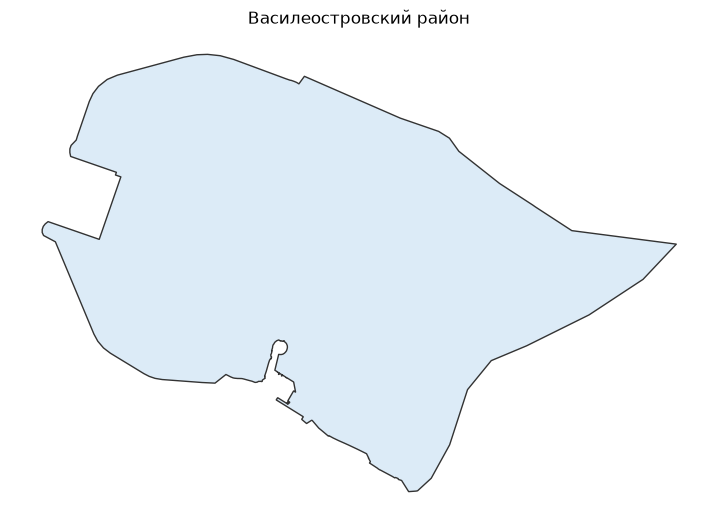

In [6]:
ax = boundaries_utm.plot(figsize=(9, 9), color="#dcebf7", edgecolor="#333333", linewidth=1)
ax.set_title(district_name)
ax.set_axis_off()
plt.show()

## 3. Исходные слои OpenStreetMap

Скачиваем только то, что нужно для пайплайна:

- дороги — линии, по ним будут нарезаться кварталы;
- железные дороги — тоже линии;
- вода — реки, каналы, водоёмы;
- функциональные зоны (`landuse`) — для назначения землепользования;
- здания — для населения и плотностных показателей;
- школы — для обеспеченности.

Каждый слой сохраняется отдельным GeoJSON в `data/vasileostrovsky/raw/`.
При повторном запуске скачивания не будет.

In [7]:
OSM_TAGS = {
    "roads": {
        "highway": [
            "motorway", "trunk", "primary", "secondary", "tertiary",
            "motorway_link", "trunk_link", "primary_link", "secondary_link", "tertiary_link",
            "residential", "unclassified", "living_street", "pedestrian", "road",
        ],
    },
    "railways": {"railway": "rail"},
    "water": {
        "riverbank": True,
        "reservoir": True,
        "basin": True,
        "dock": True,
        "canal": True,
        "pond": True,
        "natural": ["water", "bay"],
        "waterway": ["river", "canal", "ditch"],
        "landuse": "basin",
        "water": "lake",
    },
}
print("Теги OSM подготовлены.")

Теги OSM подготовлены.


### 3.0. Как устроена загрузка и что уже скачано

Overpass (сервер OpenStreetMap) иногда отвечает медленно. Поэтому загрузка
устроена так:

- таймаут одного запроса — 300 секунд;
- при ошибке ноутбук пробует другие зеркала Overpass (всего 3 сервера);
- между попытками пауза 5 секунд;
- большая территория делится на куски примерно по 5 км²;
- всего 3 круга попыток.

Если ячейка всё равно упала, это не страшно: **уже скачанные слои остались
на диске**. Подождите 5–10 минут и запустите упавшую ячейку снова —
остальные файлы повторно скачиваться не будут.

Ячейка ниже показывает текущее состояние папки `raw/`.

In [8]:
EXPECTED_RAW_LAYERS = {
    "boundary.geojson": "граница района",
    "roads.geojson": "дороги",
    "railways.geojson": "железные дороги",
    "water.geojson": "вода",
    "functional_zones.geojson": "функциональные зоны",
    "buildings.geojson": "здания",
    "schools.geojson": "школы",
}

raw_status = pd.DataFrame(
    [
        {
            "Файл": filename,
            "Слой": label,
            "Есть": "да" if (RAW_DIR / filename).exists() else "нет",
            "Размер, КБ": (
                round((RAW_DIR / filename).stat().st_size / 1024, 1)
                if (RAW_DIR / filename).exists()
                else 0
            ),
        }
        for filename, label in EXPECTED_RAW_LAYERS.items()
    ]
)

display(raw_status)

missing_layers = raw_status.loc[raw_status["Есть"] == "нет", "Слой"].tolist()
if missing_layers:
    print("Ещё не скачано:", ", ".join(missing_layers))
    print("Запустите соответствующие ячейки ниже. Готовые файлы не скачиваются заново.")
else:
    print("Все слои на месте.")

,Файл,Слой,Есть,"Размер, КБ"
0,boundary.geojson,граница района,да,8.5
1,roads.geojson,дороги,нет,0.0
2,railways.geojson,железные дороги,да,12.3
3,water.geojson,вода,да,15131.8
4,functional_zones.geojson,функциональные зоны,да,2417.5
5,buildings.geojson,здания,да,6817.6
6,schools.geojson,школы,да,110.0


Ещё не скачано: дороги
Запустите соответствующие ячейки ниже. Готовые файлы не скачиваются заново.


### 3.1. Дороги

Дороги нужны как линии, которые делят территорию на кварталы.

In [9]:
import geopandas as gpd
from pathlib import Path

# Ищем файл с дорогами в папке Загрузки
downloads = Path.home() / "Downloads"
candidates = list(downloads.glob("*roads*.geojson"))  # ищем любой файл, где в имени есть "roads"

print("Найдено файлов с дорогами:", [p.name for p in candidates])

if not candidates:
    raise FileNotFoundError("❌ Не найдено ни одного файла с дорогами (*roads*.geojson) в папке Downloads. Скачай файл заново.")

# Берём первый найденный (если их несколько — лучше проверить вручную, какой нужный)
file_path = candidates[0]
print(f"✅ Используем файл: {file_path.name}")

# Загружаем сразу в переменную roads — её потом передадим в BlocksNet
roads = gpd.read_file(file_path)

print(f"✅ Загружено линий: {len(roads)}")
print("Типы геометрии:", roads.geometry.type.value_counts())
print("Готово! Переменная 'roads' готова для построения кварталов.")


Найдено файлов с дорогами: ['roads_vasileostrov.geojson']
✅ Используем файл: roads_vasileostrov.geojson
✅ Загружено линий: 1253
Типы геометрии: LineString    1253
Name: count, dtype: int64
Готово! Переменная 'roads' готова для построения кварталов.


### 3.2. Железные дороги

Железные дороги тоже используются как линии разреза.

In [10]:
target = RAW_DIR / "railways.geojson"
if target.exists():
    target.unlink()
    print("Удалила неправильный railways.geojson")
else:
    print("Файла и так нет")


Удалила неправильный railways.geojson


In [11]:
import shutil
from pathlib import Path

downloads = Path.home() / "Downloads"
candidates = sorted(downloads.glob("railways*.geojson"), key=lambda p: p.stat().st_size)
print("Кандидаты в Загрузках:", [p.name for p in candidates])

if candidates:
    shutil.copy(candidates[-1], RAW_DIR / "railways.geojson")
    print("Скопировано в", RAW_DIR / "railways.geojson")
else:
    print("В Загрузках нет файла, начинающегося на railways")


Кандидаты в Загрузках: ['railways.geojson']
Скопировано в /Users/polina/python-package-boilerplate/notebooks/cache/data/vasileostrovsky/raw/railways.geojson


In [12]:
railways = load_osm_layer(
    "railways.geojson",
    OSM_TAGS["railways"],
    ["railway", "name"],
    ["LineString", "MultiLineString"],
    "Железные дороги",
)

Железные дороги: 10 объектов (из кэша)


### 3.3. Вода

Воду берём и полигонами, и линиями: реки и каналы могут быть представлены
по-разному. Полигоны воды исключаются из кварталов.

In [13]:
import shutil
from pathlib import Path

downloads = Path.home() / "Downloads"
candidates = sorted(downloads.glob("water*.geojson"), key=lambda p: p.stat().st_size)
print("Кандидаты в Загрузках:", [p.name for p in candidates])

if candidates:
    shutil.copy(candidates[-1], RAW_DIR / "water.geojson")
    print("Скопировано в", RAW_DIR / "water.geojson")
    print("Размер, КБ:", round((RAW_DIR / "water.geojson").stat().st_size / 1024, 1))
else:
    print("В Загрузках нет файла, начинающегося на water")


Кандидаты в Загрузках: ['water.geojson']
Скопировано в /Users/polina/python-package-boilerplate/notebooks/cache/data/vasileostrovsky/raw/water.geojson
Размер, КБ: 15131.8


In [14]:
import geopandas as gpd

gdf = gpd.read_file(RAW_DIR / "water.geojson")
print("Объектов:", len(gdf))
print("Колонки:", [c for c in gdf.columns if c != "geometry"])
print("Типы геометрии:", gdf.geom_type.unique().tolist())
for col in ("natural", "waterway", "water", "landuse"):
    if col in gdf.columns:
        print(f"{col}:", gdf[col].value_counts(dropna=False).head(5).to_dict())


Объектов: 19
Колонки: ['id', '@id', 'admin_level', 'boat', 'boundary', 'destination', 'gns:dsg', 'gns:uni', 'gvr:code', 'have_riverbank', 'int_name', 'intermittent', 'is_in:ocean', 'is_in:sea', 'name', 'name:ar', 'name:be', 'name:br', 'name:ca', 'name:cs', 'name:csb', 'name:da', 'name:de', 'name:en', 'name:eo', 'name:es', 'name:et', 'name:fa', 'name:fi', 'name:fr', 'name:hu', 'name:is', 'name:it', 'name:la', 'name:lt', 'name:lv', 'name:mk', 'name:nl', 'name:nn', 'name:no', 'name:pl', 'name:pt', 'name:ro', 'name:ru', 'name:sk', 'name:sv', 'name:uk', 'name:vi', 'name:zh', 'natural', 'old_name', 'type', 'water', 'waterway', 'wikidata', 'wikimedia_commons', 'wikipedia', '@relations', 'wikipedia:ru']
Типы геометрии: ['Polygon', 'LineString']
natural: {'water': 12, None: 5, 'bay': 2}
waterway: {None: 14, 'river': 4, 'canal': 1}
water: {None: 14, 'river': 5}


In [15]:
water = load_osm_layer(
    "water.geojson",
    OSM_TAGS["water"],
    ["natural", "waterway", "landuse", "water", "name"],
    ["Polygon", "MultiPolygon", "LineString", "MultiLineString"],
    "Вода",
)

Вода: 19 объектов (из кэша)


### 3.4. Функциональные зоны

Это категории землепользования из OSM: жилая застройка, коммерция,
промышленность, рекреация и т.д. Позже мы переведём их в категории BlocksNet.

In [16]:
import shutil
from pathlib import Path

downloads = Path.home() / "Downloads"
candidates = sorted(downloads.glob("functional_zones*.geojson"), key=lambda p: p.stat().st_size)
print("Кандидаты в Загрузках:", [p.name for p in candidates])

if candidates:
    shutil.copy(candidates[-1], RAW_DIR / "functional_zones.geojson")
    print("Скопировано в", RAW_DIR / "functional_zones.geojson")
    print("Размер, КБ:", round((RAW_DIR / "functional_zones.geojson").stat().st_size / 1024, 1))
else:
    print("В Загрузках нет файла, начинающегося на functional_zones")


Кандидаты в Загрузках: ['functional_zones.geojson']
Скопировано в /Users/polina/python-package-boilerplate/notebooks/cache/data/vasileostrovsky/raw/functional_zones.geojson
Размер, КБ: 2417.5


In [17]:
import shutil
from pathlib import Path

downloads = Path.home() / "Downloads"
candidates = sorted(downloads.glob("functional_zones*.geojson"), key=lambda p: p.stat().st_size)
print("Кандидаты в Загрузках:", [p.name for p in candidates])

if candidates:
    shutil.copy(candidates[-1], RAW_DIR / "functional_zones.geojson")
    print("Скопировано в", RAW_DIR / "functional_zones.geojson")
    print("Размер, КБ:", round((RAW_DIR / "functional_zones.geojson").stat().st_size / 1024, 1))
else:
    print("В Загрузках нет файла, начинающегося на functional_zones")


Кандидаты в Загрузках: ['functional_zones.geojson']
Скопировано в /Users/polina/python-package-boilerplate/notebooks/cache/data/vasileostrovsky/raw/functional_zones.geojson
Размер, КБ: 2417.5


In [18]:
functional_zones = load_osm_layer(
    "functional_zones.geojson",
    {"landuse": True},
    ["landuse", "name"],
    ["Polygon", "MultiPolygon"],
    "Функциональные зоны",
)

Функциональные зоны: 2223 объектов (из кэша)


### 3.5. Здания

Из OSM берём контуры зданий и, если есть, этажность (`building:levels`).
Остальные параметры BlocksNet дозаполнит сам.

In [19]:
import shutil
from pathlib import Path

downloads = Path.home() / "Downloads"
candidates = sorted(downloads.glob("buildings*.geojson"), key=lambda p: p.stat().st_size)
print("Кандидаты в Загрузках:", [p.name for p in candidates])

if candidates:
    shutil.copy(candidates[-1], RAW_DIR / "buildings.geojson")
    print("Скопировано в", RAW_DIR / "buildings.geojson")
    print("Размер, КБ:", round((RAW_DIR / "buildings.geojson").stat().st_size / 1024, 1))
else:
    print("В Загрузках нет файла, начинающегося на buildings")


Кандидаты в Загрузках: ['buildings.geojson']
Скопировано в /Users/polina/python-package-boilerplate/notebooks/cache/data/vasileostrovsky/raw/buildings.geojson
Размер, КБ: 6817.6


In [20]:
import geopandas as gpd

gdf = gpd.read_file(RAW_DIR / "buildings.geojson")
print("Объектов:", len(gdf))
print("Колонки:", [c for c in gdf.columns if c != "geometry"])
print("Типы геометрии:", gdf.geom_type.unique().tolist())
if "building" in gdf.columns:
    print("Значения building:", gdf["building"].value_counts(dropna=False).head(10).to_dict())
else:
    print("Колонки building НЕТ — файл не тот")
if "building_levels" in gdf.columns:
    known = gdf["building_levels"].notna().sum()
    print(f"Этажность указана у {known} из {len(gdf)} зданий ({known/len(gdf):.0%})")


Объектов: 4165
Колонки: ['id', '@id', 'abandoned', 'access', 'addr2:housenumber', 'addr2:street', 'addr:city', 'addr:country', 'addr:flats', 'addr:housenumber', 'addr:letter', 'addr:postcode', 'addr:source', 'addr:street', 'addr:street2', 'alt_name', 'amenity', 'architect', 'atm', 'automated', 'beds', 'bic', 'branch', 'brand', 'brand:en', 'brand:ru', 'brand:wikidata', 'brand:wikipedia', 'breakfast', 'bridge', 'building', 'building:architecture', 'building:cladding', 'building:colour', 'building:facade:material', 'building:flats', 'building:levelPlan', 'building:levels', '@relations', 'building:levels:underground', 'building:material', 'building:material:concrete', 'building:min_level', 'building:name', 'building:part', 'building:part:use', 'building:parts', 'building:roof:levels', 'building:use', 'building:year_built', 'built', 'cafe', 'capacity', 'castle_type', 'check_date', 'check_date:compressed_air', 'check_date:opening_hours', 'company', 'compressed_air', 'construction', 'construc

In [21]:
buildings = load_osm_layer(
    "buildings.geojson",
    {"building": True},
    ["building", "building:levels", "name"],
    ["Polygon", "MultiPolygon"],
    "Здания",
)

Здания: 4165 объектов (из кэша)


### 3.6. Школы

В пайплайне BlocksNet обеспеченность показана на примере школ.
Ёмкость школы OSM часто не содержит, поэтому BlocksNet подставит
нормативное значение из своей конфигурации.

In [22]:
import shutil
from pathlib import Path

downloads = Path.home() / "Downloads"
candidates = sorted(downloads.glob("schools*.geojson"), key=lambda p: p.stat().st_size)
print("Кандидаты в Загрузках:", [p.name for p in candidates])

if candidates:
    shutil.copy(candidates[-1], RAW_DIR / "schools.geojson")
    print("Скопировано в", RAW_DIR / "schools.geojson")
    print("Размер, КБ:", round((RAW_DIR / "schools.geojson").stat().st_size / 1024, 1))
else:
    print("В Загрузках нет файла, начинающегося на schools")


Кандидаты в Загрузках: ['schools.geojson']
Скопировано в /Users/polina/python-package-boilerplate/notebooks/cache/data/vasileostrovsky/raw/schools.geojson
Размер, КБ: 110.0


In [23]:
import geopandas as gpd

gdf = gpd.read_file(RAW_DIR / "schools.geojson")
print("Объектов:", len(gdf))
print("Колонки:", [c for c in gdf.columns if c != "geometry"])
print("Типы геометрии:", gdf.geom_type.unique().tolist())
if "amenity" in gdf.columns:
    print("Значения amenity:", gdf["amenity"].value_counts(dropna=False).to_dict())
else:
    print("Колонки amenity НЕТ — файл не тот")


Объектов: 57
Колонки: ['id', '@id', 'addr:city', 'addr:country', 'addr:housenumber', 'addr:street', 'alt_name', 'amenity', 'barrier', 'building', 'building:architecture', 'building:levels', 'check_date', 'contact:email', 'contact:phone', 'contact:vk', 'contact:website', 'description', 'education', 'education_form:fulltime', 'education_form:parttime', 'education_level:primary', 'education_level:secondary', 'education_profile:general', 'education_profile:languages', 'education_profile:visual_art', 'education_programme:FR', 'education_system:ru_standard', 'fee', 'fixme', 'level', 'max_age', 'min_age', 'name', 'name:ru', 'official_name', 'opening_hours', 'operator:type', 'ownership', 'preschool', 'ref', 'short_name', 'start_date', 'training', 'type', 'wheelchair']
Типы геометрии: ['Polygon', 'Point']
Значения amenity: {'school': 57}


In [24]:
schools = load_osm_layer(
    "schools.geojson",
    {"amenity": "school"},
    ["amenity", "name", "capacity"],
    ["Polygon", "MultiPolygon", "Point"],
    "Школы",
)

Школы: 57 объектов (из кэша)


### 3.7. Общая карта исходных слоёв

Проверяем глазами: граница, вода, дороги и железные дороги должны
соответствовать району.

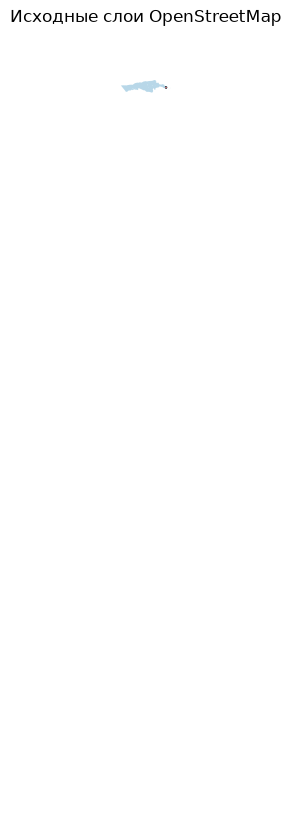

In [25]:
fig, ax = plt.subplots(figsize=(10, 10))
boundaries_utm.boundary.plot(ax=ax, color="#222222", linewidth=1.2)
water.plot(ax=ax, color="#a6cee3", alpha=0.8)
functional_zones.plot(ax=ax, color="#b2df8a", alpha=0.25)
roads.plot(ax=ax, color="#888888", linewidth=0.4)
railways.plot(ax=ax, color="#e45756", linewidth=0.8)
ax.set_title("Исходные слои OpenStreetMap")
ax.set_axis_off()
plt.show()

## 4. Кварталы

Кварталы — это замкнутые участки между дорогами, железными дорогами и водой.
BlocksNet сначала готовит линии и полигоны, а затем нарезает ими границу района.

Если файл `processed/blocks.geojson` уже есть, нарезка не повторяется.

In [26]:
import logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(name)s | %(message)s")
print("Логи включены")


Логи включены


In [27]:
print("Колонки:", roads.columns.tolist())
print("Типы геометрии:", roads.geom_type.value_counts().to_dict())
print("CRS:", roads.crs)
print("Пустая геометрия:", roads.geometry.is_empty.sum(), "| NaN:", roads.geometry.isna().sum())
if "highway" in roads.columns:
    print("Пустых highway:", roads["highway"].isna().sum())
if "name" in roads.columns:
    print("Типы в name:", roads["name"].map(type).value_counts().to_dict())


Колонки: ['id', '@id', 'access', 'access:conditional', 'admin_level', 'alt_name', 'bicycle', 'boundary', 'bridge', 'bridge:movable', 'bus_bay', 'check_date', 'class:bicycle', 'covered', 'cutting', 'cycleway:right', 'description', 'destination', 'destination:lanes', 'destination:ref:lanes', 'destination:symbol', 'fixme', 'foot', 'hazard', 'hgv', 'highway', 'junction', 'junction:ref', 'lane_markings', 'lanes', 'lanes:backward', 'lanes:forward', 'layer', 'lit', 'living_street', 'loc_name', 'maxaxleload', 'maxheight', 'maxspeed', 'maxspeed:type', 'maxweight', 'maxweight:signed', 'motor_vehicle', 'name', 'name:de', 'name:en', 'name:etymology:wikidata', 'name:fr', 'name:left', 'name:right', 'name:ru', 'name:source', 'name:uk', 'name:zh', 'noname', 'note', 'old_name', 'old_name:de', 'oneway', 'parking:both', 'parking:both:orientation', 'parking:both:restriction', 'parking:condition:right', 'parking:lane:both', 'parking:lane:left', 'parking:lane:right', 'parking:lane:right:parallel', 'parking:

In [28]:
import blocksnet.blocks.cutting.preprocessing.core as core

try:
    core.RoadsSchema(roads)
    print("Валидация прошла — значит, дело было в устаревших данных")
except Exception as e:
    print("Поймала ошибку:", type(e).__name__)
    print(str(e)[:3000])


2026-10-31 21:50:01.820 | WARNING  | blocksnet.utils.validation.gdf_schema:_warn_crs:40 - Current CRS 4326 is not projected. It might cause problems when carrying out spatial operations. Recommended: EPSG:32636


Валидация прошла — значит, дело было в устаревших данных


In [29]:
import geopandas as gpd
from pathlib import Path

# Ищем файл с дорогами прямо в Downloads
downloads = Path.home() / "Downloads"
candidates = list(downloads.glob("*roads*.geojson"))

if not candidates:
    raise FileNotFoundError("❌ Не найдено ни одного файла с дорогами (*roads*.geojson) в папке Downloads.")

file_path = candidates[0]
print(f"✅ Используем файл: {file_path}")

# Читаем файл
gdf = gpd.read_file(file_path)

# Проверяем геометрию (то, что ты хотела сделать в том коде)
print("Типы геометрии:", gdf.geom_type.value_counts().to_dict())
print("Невалидных геометрий:", (~gdf.geometry.is_valid).sum())
print("Пустых:", gdf.geometry.is_empty.sum(), "| NaN:", gdf.geometry.isna().sum())

invalid = gdf[~gdf.geometry.is_valid]
if len(invalid):
    print("Примеры проблемных типов:", invalid.geom_type.value_counts().to_dict())
else:
    print("✅ Проблемных геометрий нет — файл чистый!")

print(f"✅ Готово! В переменной gdf теперь {len(gdf)} линий.")


✅ Используем файл: /Users/polina/Downloads/roads_vasileostrov.geojson
Типы геометрии: {'LineString': 1253}
Невалидных геометрий: 0
Пустых: 0 | NaN: 0
✅ Проблемных геометрий нет — файл чистый!
✅ Готово! В переменной gdf теперь 1253 линий.


In [30]:
from blocksnet.quarters import build_quarters

territory_id = 187530  # OSM ID Васильевского острова

print(f"🗺️ Строим кварталы для территории {territory_id}...")
quarters = build_quarters(roads=gdf, territory_id=territory_id)  # <-- передаём gdf

print("✅ Кварталы построены!")
print(quarters.head())
print(f"Всего кварталов: {len(quarters)}")


ModuleNotFoundError: No module named 'blocksnet.quarters'

In [ ]:
import geopandas as gpd

gdf = gpd.read_file(RAW_DIR / "roads.geojson")
print("Объектов:", len(gdf))
print("Колонки:", gdf.columns.tolist())
print("Типы геометрии:", gdf.geom_type.value_counts().to_dict())
print(gdf.drop(columns="geometry").head(3))

DataSourceError: /Users/polina/python-package-boilerplate/notebooks/cache/data/vasileostrovsky/raw/roads.geojson: No such file or directory

In [ ]:
(RAW_DIR / "roads.geojson").unlink()
print("Испорченный roads.geojson удалён")


Испорченный roads.geojson удалён


In [ ]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

blocks_path = PROCESSED_DIR / "blocks.geojson"

if USE_CACHE and not FORCE_REDOWNLOAD and blocks_path.exists():
    blocks = read_geojson(blocks_path, crs)
    if "block_id" in blocks.columns:
        blocks["block_id"] = blocks["block_id"].astype(int)
        blocks = blocks.set_index("block_id")
    print(f"Кварталы: из кэша ({len(blocks)} шт.)")
else:
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundaries_utm, lines, polygons)

    blocks = blocks[blocks.geom_type.isin(["Polygon", "MultiPolygon"])].explode(index_parts=False)
    blocks = blocks[blocks.geom_type == "Polygon"].copy()
    blocks = blocks[blocks.area > 1].reset_index(drop=True)
    blocks["block_id"] = range(len(blocks))
    blocks = blocks.set_index("block_id")
    blocks.index.name = "block_id"
    blocks["site_area"] = blocks.area

    write_geojson(blocks.reset_index(), blocks_path)
    print(f"Кварталы: нарезаны ({len(blocks)} шт.)")

blocks.index.name = "block_id"
blocks["site_area"] = blocks.area
print(f"Площадь кварталов: {blocks['site_area'].sum() / 1e6:.2f} км²")

2026-10-31 21:05:41.818 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-31 21:05:41.967 | ERROR    | blocksnet.utils.validation.df_schema:_log_schema_errors:72 - Schema validation errors:
14 column-level errors at column "geometry" at check "_check_geometry": 0, 1, 2, 3, 4, ...


ValueError: RoadsSchema validation failed. Please check log and verify data according to schema

In [ ]:
ax = blocks.plot(figsize=(10, 10), color="#f2f2f2", edgecolor="#777777", linewidth=0.3)
ax.set_title(f"Кварталы Василеостровского района: {len(blocks)} шт.")
ax.set_axis_off()
plt.show()

### 4.1. Землепользование кварталов

Каждому кварталу назначаем преобладающую категорию землепользования.
Для этого переводим категории OSM в категории BlocksNet по правилам ниже.

Категории, которых нет в правилах, будут перечислены в предупреждении.
Это нормально: часть тегов OSM не имеет прямого аналога.

In [ ]:
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

LAND_USE_RULES = {
    "residential": LandUse.RESIDENTIAL,
    "commercial": LandUse.BUSINESS,
    "retail": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "garages": LandUse.INDUSTRIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "quarry": LandUse.INDUSTRIAL,
    "construction": LandUse.SPECIAL,
    "cemetery": LandUse.SPECIAL,
    "religious": LandUse.SPECIAL,
    "military": LandUse.SPECIAL,
    "grass": LandUse.RECREATION,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "flowerbed": LandUse.RECREATION,
    "village_green": LandUse.RECREATION,
    "park": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "meadow": LandUse.AGRICULTURE,
    "orchard": LandUse.AGRICULTURE,
    "allotments": LandUse.AGRICULTURE,
    "railway": LandUse.TRANSPORT,
    "landfill": LandUse.TRANSPORT,
    "port": LandUse.TRANSPORT,
}

functional_zones_for_assign = functional_zones.copy()
functional_zones_for_assign = functional_zones_for_assign.rename(columns={"landuse": "functional_zone"})
functional_zones_for_assign["functional_zone"] = functional_zones_for_assign["functional_zone"].map(_first)
functional_zones_for_assign = functional_zones_for_assign.dropna(subset=["functional_zone"])
functional_zones_for_assign["functional_zone"] = functional_zones_for_assign["functional_zone"].astype(str)
functional_zones_for_assign = functional_zones_for_assign[
    functional_zones_for_assign.geom_type.isin(["Polygon", "MultiPolygon"])
]

blocks = assign_land_use(blocks, functional_zones_for_assign, LAND_USE_RULES)
blocks["land_use"] = blocks["land_use"].apply(lambda value: value.value if hasattr(value, "value") else value)
blocks.index.name = "block_id"
# assign_land_use оставляет только геометрию, поэтому площадь нужно добавить снова
blocks["site_area"] = blocks.area
if "share" in blocks.columns:
    blocks = blocks.rename(columns={"share": "land_use_share"})

write_geojson(blocks.reset_index(), PROCESSED_DIR / "blocks_land_use.geojson")
print("Землепользование назначено.")
print(blocks["land_use"].value_counts(dropna=False).to_string())

In [ ]:
ax = blocks.plot(
    column="land_use",
    categorical=True,
    legend=True,
    figsize=(10, 10),
    cmap="Set3",
    edgecolor="#777777",
    linewidth=0.3,
    missing_kwds={"color": "#dddddd", "label": "не назначено"},
)
ax.set_title("Землепользование кварталов")
ax.set_axis_off()
plt.show()

## 4.2. Справочник метрик: что умеет BlocksNet и что считаем мы

Этот раздел — словарь, а не расчёт: здесь ничего не вычисляется.
Его можно читать до запуска, во время и после. Он нужен, чтобы
к остановке 🛑 мы называли одни и те же вещи одинаково.

### 4.2.1. Три уровня измерений

| Уровень | Что это | Пример |
|---|---|---|
| Показатель квартала | одно число на каждый квартал | плотность застройки, население, обеспеченность школами |
| Показатель пары кварталов | таблица «квартал × квартал» | время в пути из квартала A в квартал B |
| Показатель объекта | число у здания, школы, магазина | ёмкость школы, этажность здания |

Квартал (`block`) — участок территории, ограниченный дорогами, водой
и железными дорогами. Все результаты BlocksNet привязаны к номеру
квартала `block_id`. Поэтому их можно соединить в одну таблицу и
показать на карте: одна строка — один квартал, один столбец — один показатель.

### 4.2.2. Единицы измерения, принятые в BlocksNet

| Что измеряем | Единица | Как читать |
|---|---|---|
| Площади | м² | в сводках переводим в км² (1 км² = 1 000 000 м²) |
| Время | минуты | время в пути по сети, не «по прямой» |
| Расстояния по сети | метры | длина маршрута |
| Расстояния по прямой | метры | евклидово расстояние между точками |
| Доли и коэффициенты | безразмерные | чаще от 0 до 1, иногда больше |
| Этажность | этажи | средняя этажность квартала |
| Ёмкость услуг | места | места в школе, койки в больнице, посещения |
| Население | человек | оценка, а не перепись |

Важно про плотность: **FSI** формально выражается в м²/м², но это
безразмерная величина. `FSI = 2.0` значит «на 1 м² земли приходится
2 м² этажей». **GSI** — доля земли под зданиями, тоже безразмерная.

### 4.2.3. Что BlocksNet умеет: карта возможностей

В версии 1.0.0a9 есть десять групп методов. Не все они нужны в нашем
исследовании, но полезно знать, что бывает.

| Группа | Что считает | Главный вопрос, на который отвечает | Единицы |
|---|---|---|---|
| Геометрия кварталов | площадь, периметр, центры, радиусы, вытянутость | какой формы кварталы | м², м, безразмерные |
| Плотность и застройка | FSI, GSI, MXI, L, OSR, доли площадей | насколько плотно и как застроено | безразмерные, м² |
| Морфотипы | Spacematrix (кластеры) и Strelka (правила) | какой это тип застройки | текст, номер кластера |
| Доступность сети | матрица времени, среднее, медиана, максимум, доступность территории | сколько минут до других кварталов | минуты |
| Обеспеченность услугами | простая и конкурентная обеспеченность | хватает ли школ, садиков, поликлиник | доли 0..1, места |
| Центральность | по населению и по услугам | какие кварталы «в центре событий» | 0..1 |
| Разнообразие и услуги | индекс Шеннона, число и плотность услуг, совместная встречаемость | насколько разнообразна среда | безразмерные, шт. |
| Землепользование | доли, нормативные показатели, похожесть, соседство, предсказание | как используется земля | доли 0..1, м² |
| Пустующие территории | участки без застройки | где есть свободная земля | м², м |
| Транспортная нагрузка | матрица корреспонденций и загрузка рёбер графа | куда едут люди и где узкие места | поездки, условные единицы |

Коротко о каждой группе:

- **Геометрия** — не про городскую жизнь, а про форму участков.
  Помогает понять, почему квартал плохо обслуживается: например,
  длинный узкий квартал неудобен для школы в центре.
- **Плотность и застройка** — количественная основа всех разговоров
  о «переуплотнении» и «недостатке дворов».
- **Морфотипы** — попытка назвать тип застройки словами:
  «среднеэтажная микрорайонная», «высотная современная» и т.д.
- **Доступность** — сколько минут занимает дорога. Это база для
  обеспеченности: услуга рядом только тогда, когда до неё можно дойти.
- **Обеспеченность** — сравнение потребности и ёмкости услуг.
  Самый практичный блок для управленческих выводов.
- **Центральность** — какие кварталы притягивают людей и услуги.
- **Разнообразие** — есть ли в квартале разные услуги или только один тип.
- **Землепользование** — как распределена земля по категориям.
- **Пустующие территории** — где потенциально можно строить.
- **Транспортная нагрузка** — требует матрицы корреспонденций,
  то есть данных о поездках. Для нашего этапа это избыточно.

### 4.2.4. Все показатели из `pipeline.ipynb`

Ниже — ровно тот набор, который считается в `examples/pipeline.ipynb`
версии 1.0.0a9. Мы повторяем его с двумя отличиями:

1. В пайплайне граф **интермодальный** (пешком + транспорт),
   у нас — **пешеходный** со скоростью 5 км/ч.
2. Правила землепользования мы задаём свои, более полные.

#### 1. Матрица доступности

| Показатель | Что означает простыми словами | Единица | Что скажет о городе |
|---|---|---|---|
| `accessibility_matrix` (`acc_mx`) | сколько минут идти от каждого квартала до каждого другого | минуты | насколько район связный: есть ли кварталы-«отрезанные», где всё далеко |

Матрица квадратная: строк столько же, сколько столбцов, и равно числу
кварталов. На диагонали — время квартала до самого себя, то есть ноль.

#### 2. Здания и население

| Показатель | Что означает простыми словами | Единица | Что скажет о городе |
|---|---|---|---|
| `population` | сколько человек живёт в квартале | человек | где живёт больше всего людей, где район «спальный» |
| `footprint_area` | площадь пятна застройки: сколько земли занимают здания | м² | насколько плотно занята земля |
| `number_of_floors` | этажность здания | этажи | историческая застройка или новостройки |
| `build_floor_area` | суммарная поэтажная площадь: пятно × этажность | м² | общий объём застройки |
| `is_living` | жилое здание или нет | да/нет | где жильё, а где офисы и производство |
| `living_area` | площадь, отданная под жильё | м² | жилой фонд квартала |
| `non_living_area` | площадь под нежилые нужды | м² | коммерция, офисы, учреждения |

Напоминание: население BlocksNet оценивает по формуле
«жилая площадь ÷ 30 м² на человека». Это оценка, а не перепись.

#### 3. Услуги и ёмкость

| Показатель | Что означает простыми словами | Единица | Что скажет о городе |
|---|---|---|---|
| `capacity` | сколько мест даёт услуга в квартале (для школ — мест) | места | где сосредоточены школы |
| `demand` | нормативная потребность: население × норматив ÷ 1000 | места | сколько мест должно быть по нормативу |

#### 4. Обеспеченность школами (`competitive_provision`)

Смысл метода: распределить учеников по школам так, чтобы каждому
хватило места, а ехать было недалеко. Норматив для школ в BlocksNet:
**120 мест на 1000 жителей**, радиус **15 минут**.

| Показатель | Что означает простыми словами | Единица | Что скажет о городе |
|---|---|---|---|
| `demand` | сколько мест нужно жителям квартала | места | нагрузка на сеть школ |
| `capacity` | сколько мест есть в квартале | места | предложение |
| `demand_within` | сколько потребности закрыто в пределах 15 минут | места | нормально обслуживаемая часть |
| `demand_without` | сколько закрыто за пределами радиуса | места | «вынужденные» поездки |
| `demand_left` | сколько потребности осталось без места | места | дефицит |
| `capacity_within` | ёмкость, использованная в пределах радиуса | места | загрузка школ |
| `capacity_without` | ёмкость, использованная за радиусом | места | школы, работающие на дальние кварталы |
| `capacity_left` | свободные места | места | резерв |
| `provision_strong` | доля потребности, закрытая строго по нормативу | 0..1 | «формальная» обеспеченность |
| `provision_weak` | доля потребности с учётом поездок за радиус | 0..1 | «фактическая» обеспеченность |
| `provision_links` (`source`, `target`, `value`) | кто кого обслуживает и сколько человек | человек | связи между кварталами |

Тонкость: при глубине расчёта 1 (по умолчанию) все связи укладываются
в радиус, поэтому `provision_weak` совпадает с `provision_strong`.
Разница появляется при глубине 2 и больше. В нашем ноутбуке глубина
по умолчанию, так что числа совпадут — это не ошибка.

#### 5. Плотность и застройка (`calculate_density_indicators`)

| Показатель | Что означает простыми словами | Единица | Что скажет о городе |
|---|---|---|---|
| `site_area` | площадь квартала | м² | размер «единицы анализа» |
| `fsi` | сколько м² этажей на 1 м² земли | безразмерный | плотность застройки: 0.5 — малоэтажная, 3 — очень плотная |
| `gsi` | какая доля квартала занята зданиями | 0..1 | теснота: высокий GSI — мало открытой земли |
| `mxi` | какая доля этажей отдана под жильё | 0..1 | жилой это квартал или офисно-деловой |
| `l` | средняя этажность | этажи | 2–3 — историческая, 5–6 — доходные дома, 9–12 — советские, 20+ — новые |
| `osr` | сколько открытого пространства на 1 м² застройки | м²/м² | есть ли дворы и скверы при такой плотности |
| `share_living` | жилая площадь на 1 м² пятна застройки | м²/м² | насколько «жилой» фонд |
| `share_non_living` | нежилая площадь на 1 м² пятна застройки | м²/м² | сколько коммерции и учреждений |

Как читать вместе: высокий **FSI** при низком **OSR** — плотно застроено
и мало открытого пространства. Высокий **GSI** при низком **L** —
мелкая застройка, занимающая много земли. Низкий **MXI** — квартал
скорее деловой или промышленный, чем жилой.

#### 6. Морфотипы

Два независимых способа назвать тип застройки.

**Spacematrix** (`get_spacematrix_morphotypes`): кварталы делятся
на 11 кластеров автоматически, по трём числам — `l`, `fsi`, `mxi`.
Затем каждый кластер получает словесное имя.

| Показатель | Что означает | Единица |
|---|---|---|
| `spacematrix_cluster` | номер кластера | 0..10 |
| `morphotype` | название кластера словами | текст |
| `spacematrix_clusters` | таблица: медианы `l`, `fsi`, `mxi` по кластерам | этажи, безразмерные |

Название собирается из трёх частей: этажность (`low-rise`, `mid-rise`,
`high-mid-rise`, `high-rise`, `tower`), плотность (`low-density`,
`high-density`) и доля жилья (`non-residential`, `mixed-use`, `residential`).
Например: «mid-rise low-density residential».

**Strelka** (`get_strelka_morphotypes`): не кластеризация, а жёсткие
правила по этажности и плотности. Типов 11:

- `low-rise non-residential` — малоэтажное нежилое;
- `individual residential` — индивидуальная жилая застройка;
- `low-rise model` — малоэтажная жилая модель;
- `mid-rise` — среднеэтажная застройка общего типа;
- `mid-rise non-residential` — среднеэтажное нежилое;
- `mid-rise microdistrict` — среднеэтажный микрорайон;
- `mid-rise block` — среднеэтажный квартал;
- `central model` — «центральная модель»: плотно и много жилья;
- `high-rise non-residential` — высотное нежилое;
- `high-rise soviet microdistrict` — советский высотный микрорайон;
- `high-rise modern microdistrict` — современный высотный микрорайон.

Морфотипы — это описание, а не оценка «хорошо/плохо». Одинаковый тип
может быть уютным и неуютным: важны дворы, услуги, доступность.

#### 7. Доступность территории (`area_accessibility`)

| Показатель | Что означает простыми словами | Единица | Что скажет о городе |
|---|---|---|---|
| `area_accessibility` | среднее время до всех кварталов, взвешенное по их площади | минуты | насколько квартал «в центре событий»; меньше — удобнее |

Считается честнее, чем просто среднее: большие кварталы влияют сильнее,
маленькие — слабее.

#### 8. Альтернативные способы задать отношения между кварталами

В пайплайне упоминаются, но не считаются:

- **матрица расстояний** (`calculate_distance_matrix`) — расстояние
  по прямой между центрами кварталов, метры;
- **граф смежности** (`generate_adjacency_graph`) — узлы-кварталы,
  рёбра между соседями, которые касаются друг друга.

Они нужны для других методов: например, граф смежности используется
в центральности по населению и в соседстве землепользований.

### 4.2.5. Метрики BlocksNet за пределами `pipeline.ipynb`

Эти показатели в пайплайне не считаются, но есть в библиотеке.
Полезно знать, если захотите расширить исследование.

**Доступность** (`blocksnet.analysis.network`):

- `mean_accessibility`, `median_accessibility`, `max_accessibility` —
  среднее, медианное и максимальное время до других кварталов, минуты;
- `relative_accessibility` — время до одного выбранного квартала, минуты;
- `land_use_accessibility` — время до кварталов с нужной категорией земли
  (например, до жилых), минуты;
- `land_use_accessibility_matrix` — таблица «категория → категория», минуты;
- `connectivity` — 1 ÷ доступность, 1/мин: чем больше, тем связнее квартал.

**Центральность** (`blocksnet.analysis.centrality`):

- `population_centrality` — сочетание числа жителей и числа соседних
  кварталов, 0..1;
- `services_centrality` — сочетание связности, разнообразия и плотности
  услуг, 0..1.

**Разнообразие и услуги** (`blocksnet.analysis.diversity`,
`blocksnet.analysis.services`):

- `shannon_diversity` — индекс Шеннона по типам услуг: 0 — услуга
  одного типа; чем больше разных типов, тем выше (логарифмическая шкала);
- `services_count` — число объектов услуг, шт.;
- `services_density` — число объектов на м² (умножьте на 1 000 000,
  чтобы получить объектов на км²);
- `services_collocation` — как часто разные услуги встречаются
  в одном квартале, доля 0..1.

**Землепользование** (`blocksnet.analysis.land_use`):

- `calculate_land_use_shares` — доли категорий по площади, 0..1;
- `calculate_land_use_indicators` — нормативная оценка застройки
  и населения по категориям земли;
- `land_use_similarity` — насколько набор услуг квартала похож
  на типичный для категории, 0..1 плюс предсказанная категория;
- `land_use_collocation` — какие категории земли соседствуют;
- предсказание землепользования (машинное обучение) — экспериментальный
  метод, требует обучающих данных.

**Геометрия** (`blocksnet.analysis.geometry`):

- `site_length` — периметр квартала, м;
- `x`, `y` — координаты центра, м (в локальной проекции);
- `outer_radius` — радиус описанной окружности, м;
- `inner_radius` — радиус вписанной окружности, м;
- `aspect_ratio` — вытянутость квартала (отношение сторон), безразмерная;
- `calculate_centerlines` — осевые линии квартала.

**Пустующие территории** (`blocksnet.analysis.vacant_area`):

- `get_vacant_areas` — участки без застройки с показателями
  `area` (м²), `mrr_area` (м²), `length` (м),
  `area_to_length` (м), `area_to_mrr_area` (безразмерный).

**Транспортная нагрузка** (`blocksnet.analysis.network`):

- `origin_destination_matrix` — матрица корреспонденций, поездки;
- `road_congestion` — суммарная нагрузка на каждое ребро графа.

Последняя группа требует данных о поездках людей, которых у нас нет.
Поэтому в исследовании мы её не используем.

### 4.2.6. Нормативы обеспеченности в BlocksNet

Для каждой услуги в конфигурации заданы два числа:

- **норматив** — сколько единиц услуги нужно на 1000 жителей;
- **радиус** — за сколько минут житель должен до неё добраться.

Например, для школы: 120 мест на 1000 жителей и 15 минут.
Для детского сада: 61 место на 1000 жителей и 7 минут.

Ячейка ниже просто печатает справочник из конфигурации библиотеки.
Она ничего не считает и в интернет не ходит.

In [ ]:
from blocksnet.config import service_types_config

norms_df = pd.DataFrame(
    [
        {
            "Код": code,
            "Услуга": values.get("name_ru", values.get("name", code)),
            "Норматив на 1000 жителей": values.get("demand"),
            "Радиус, минут": values.get("accessibility"),
        }
        for code, values in service_types_config.items()
    ]
).sort_values(["Радиус, минут", "Услуга"])

print(f"Всего типов услуг в конфигурации BlocksNet: {len(norms_df)}")
norms_df.reset_index(drop=True)

Норматив — это не истина, а договорённость. В нём зашиты представления
о «нормальном» городе. Если вы считаете, что школу должно быть видно
из окна, а не в 15 минутах, — это меняется в параметрах расчёта.

### 4.2.7. Как не обмануться в числах

Семь типичных ловушек:

1. **Данные OSM неполные.** Часть зданий и объектов не нанесена,
   у части нет этажности. Всё, что ниже, — оценка по имеющимся данным.
2. **Население — расчёт, а не перепись.** Формула «жилая площадь ÷ 30»
   может сильно расходиться с реальностью в общежитиях, новостройках
   и нежилых зданиях с «жилой» площадью.
3. **Ёмкость услуг дозаполняется нормативом.** Если в OSM нет числа
   мест, BlocksNet подставляет минимальное нормативное значение.
   Это лучше, чем ноль, но это не факт.
4. **Квартал — грубая единица.** Внутри квартала может быть и школа,
   и пустырь; показатель один на всех.
5. **Обеспеченность нормативная, а не фактическая.** Она не знает
   о переполненных классах, второй смене и выборе родителей.
6. **Морфотип — описание, а не приговор.** «Плотный» не значит «плохой».
7. **Доступность зависит от графа и скорости.** Пешком 5 км/ч,
   без транспорта и без перехода через неудобные места. Другой граф —
   другие минуты.

Поэтому итог исследования — не одна цифра, а набор показателей,
карта и честное описание ограничений.

### 4.2.8. Что именно посчитает этот ноутбук

После остановки ноутбук добавит в таблицу кварталов следующие столбцы:

| Блок | Столбцы в `blocks_metrics` |
|---|---|
| Геометрия и землепользование | `site_area`, `land_use`, `land_use_share` |
| Здания и население | `population`, `footprint_area`, `build_floor_area`, `living_area`, `non_living_area` |
| Услуги | `capacity`, `demand` |
| Плотность | `fsi`, `gsi`, `mxi`, `l`, `osr`, `share_living`, `share_non_living` |
| Морфотипы | `morphotype_spacematrix`, `spacematrix_cluster`, `morphotype_strelka` |
| Обеспеченность | `provision_strong`, `provision_weak`, `demand_within`, `demand_without` |
| Доступность | `area_accessibility` |

Отдельно сохраняются: матрица времени, связи «квартал → школа»,
описание кластеров, число кварталов по типам, сводка и паспорт запуска.

Итого 25 показателей на квартал плюс матрица и вспомогательные таблицы.
Если каких-то не хватает — самое время сказать об этом на остановке.

---
## 🛑 ОСТАНОВКА: кварталы готовы

**Дальше начинаются расчёты. Не запускайте следующие ячейки, пока мы не согласуем метрики.**

Что уже есть:

- граница района и исходные слои OSM;
- кварталы в `processed/blocks.geojson`;
- землепользование в `processed/blocks_land_use.geojson`;
- карта кварталов.

Что проверить перед продолжением:

1. Число кварталов выглядит правдоподобно.
2. На карте нет огромных «пустых» кварталов, которые попали в воду.
3. Землепользование назначено большинству кварталов.
4. Границы района совпадают с ожидаемыми.

Что нужно согласовать:

1. **Услуги.** Оставляем только школы, как в `pipeline.ipynb`,
   или добавляем детские сады (61 место на 1000, радиус 7 минут),
   поликлиники (13 на 1000, 15 минут), магазины у дома (200 на 1000,
   10 минут)? Полный список нормативов — в разделе 4.2.6.
2. **Дополнительные показатели.** Нужны ли центральность, разнообразие
   услуг по Шеннону, пустующие территории? Их описание — в разделе 4.2.5.
3. **Граф.** Оставляем пешеходный (5 км/ч) или добавляем автомобильный.

Подробное объяснение каждого показателя, его единиц и смысла —
в разделе **4.2 «Справочник метрик»** выше. Если какой-то показатель
непонятен или кажется лишним, скажите — уберём или заменим.

После согласования можно запускать ячейки ниже.

In [ ]:
print("КВАРТАЛЫ ГОТОВЫ")
print(f"Кварталов: {len(blocks)}")
print(f"Площадь: {blocks['site_area'].sum() / 1e6:.2f} км²")
print(f"Землепользование назначено: {blocks['land_use'].notna().sum()} из {len(blocks)}")
print("Дальше — расчёты. Не запускайте следующие ячейки до согласования метрик.")

## 5. Пешеходный граф и время в пути

**Выбранный граф:** пешеходная сеть OpenStreetMap (`walk`).
**Источник:** OpenStreetMap / Overpass, загрузка через IduEdu 0.4.1 и OSMnx 2.1.1.
**Способ передвижения:** пешком, скорость 5 км/ч.
**Единица времени:** минуты.

Интермодальный граф не строим. Чтобы маршруты у границы района были
реалистичными, скачиваем сеть с запасом 500 метров вокруг района.

Граф сохраняется в `processed/walk_graph.graphml`. При повторном запуске
он читается с диска.

### 5.1. Загрузка или чтение графа

In [ ]:
from blocksnet.relations import validate_accessibility_graph

graph_area_utm = boundaries_utm.copy()
graph_area_utm["geometry"] = graph_area_utm.geometry.buffer(GRAPH_BUFFER_M)
graph_area_4326 = graph_area_utm.to_crs(4326)

if USE_CACHE and not FORCE_REDOWNLOAD and GRAPH_PATH.exists():
    graph = load_walk_graph(GRAPH_PATH)
    print("Граф: из кэша")
else:
    try:
        graph = ie.get_walk_graph(
            territory=graph_area_4326.union_all(),
            walk_speed=WALK_SPEED_M_PER_MIN,
        )
    except TypeError:
        graph = ie.get_walk_graph(
            polygon=graph_area_4326.union_all(),
            walk_speed=WALK_SPEED_M_PER_MIN,
        )
    ox.save_graphml(graph, GRAPH_PATH)
    print("Граф: скачан из OpenStreetMap")

validate_accessibility_graph(graph, weight_key="time_min")
print(f"Узлов: {graph.number_of_nodes():,}")
print(f"Рёбер: {graph.number_of_edges():,}")
print(f"CRS: EPSG:{graph.graph['crs']}")
print(f"Тип графа: {graph.graph.get('type', 'walk')}")

### 5.2. Карта пешеходной сети

In [ ]:
fig, ax = ox.plot_graph(
    graph,
    node_size=0,
    edge_linewidth=0.3,
    edge_color="#888888",
    bgcolor="white",
    show=False,
    close=False,
)
boundaries_utm.boundary.plot(ax=ax, color="#222222", linewidth=1)
ax.set_title("Пешеходный граф OpenStreetMap")
plt.show()

### 5.3. Матрица времени между кварталами

Для каждой пары кварталов считаем кратчайшее время пешком между их
центральными точками. Значения — в минутах. Если пара недостижима,
в матрице будет `inf`.

In [ ]:
from blocksnet.relations import calculate_accessibility_matrix

blocks_for_matrix = blocks.copy()
acc_mx = calculate_accessibility_matrix(
    blocks_for_matrix,
    graph,
).astype(np.float32)
acc_mx.index.name = "block_id"
acc_mx.columns.name = "block_id"
acc_mx.to_csv(RESULTS_DIR / "accessibility_matrix.csv")

print(f"Размер матрицы: {acc_mx.shape[0]} × {acc_mx.shape[1]}")
print(f"Сохранено: {(RESULTS_DIR / 'accessibility_matrix.csv').relative_to(PROJECT_DIR)}")
acc_mx.iloc[:5, :5]

### 5.4. Статистика времени в пути

In [ ]:
arr = acc_mx.to_numpy(dtype=float, copy=True)
np.fill_diagonal(arr, np.nan)
finite = arr[np.isfinite(arr)]
n_unreachable = int(np.isinf(arr).sum())

if finite.size:
    print(f"Минимум: {np.nanmin(finite):.1f} мин")
    print(f"Медиана: {np.nanmedian(finite):.1f} мин")
    print(f"Среднее: {np.nanmean(finite):.1f} мин")
    print(f"Максимум: {np.nanmax(finite):.1f} мин")
    print(f"Доля пар в пределах 15 минут: {np.mean(finite <= 15):.1%}")
print(f"Недостижимых пар: {n_unreachable}")

plot_values = finite[finite <= 60]
if plot_values.size:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(plot_values, bins=30, color="#4C78A8", edgecolor="white")
    ax.set_xlabel("Время в пути, минуты")
    ax.set_ylabel("Число пар кварталов")
    ax.set_title("Распределение времени между кварталами (до 60 минут)")
    plt.show()

## 6. Здания и население

Из OSM берём контуры зданий. BlocksNet:

- считает площадь застройки;
- дозаполняет этажность, если её нет;
- оценивает жилую и нежилую площадь;
- оценивает население по норме 30 м² жилой площади на человека.

Это **оценка**, а не официальная статистика. Ограничение отмечено в выводах.

### 6.1. Очистка и дозаполнение зданий

In [ ]:
from blocksnet.preprocessing.imputing import impute_buildings

IS_LIVING_TAGS = {
    "residential", "house", "apartments", "detached", "terrace", "dormitory",
    "semi-detached", "townhouse", "bungalow", "cabin",
}

buildings_clean = buildings.copy().to_crs(crs)
buildings_clean = buildings_clean[
    buildings_clean.geom_type.isin(["Polygon", "MultiPolygon"])
].explode(index_parts=False).reset_index(drop=True)

if "building" not in buildings_clean.columns:
    buildings_clean["building"] = None
if "building_levels" not in buildings_clean.columns:
    buildings_clean["building_levels"] = None

buildings_clean["is_living"] = (
    buildings_clean["building"]
    .map(_first)
    .fillna("")
    .astype(str)
    .str.lower()
    .isin(IS_LIVING_TAGS)
)
buildings_clean["number_of_floors"] = pd.to_numeric(
    buildings_clean["building_levels"].map(_first),
    errors="coerce",
).clip(lower=0)

for column in ["footprint_area", "build_floor_area", "living_area", "non_living_area", "population"]:
    buildings_clean[column] = np.nan

# impute_buildings оставляет только расчётные колонки, тип здания сохраняем отдельно
building_types = buildings_clean["building"].copy()
buildings_clean = impute_buildings(buildings_clean)
buildings_clean["building"] = building_types.reindex(buildings_clean.index)

print(f"Зданий после очистки: {len(buildings_clean):,}")
print(f"Жилых зданий: {int(buildings_clean['is_living'].sum()):,}")
print(f"Оценка населения: {buildings_clean['population'].sum():,.0f} чел.")

### 6.2. Агрегация зданий по кварталам

In [ ]:
from blocksnet.blocks.aggregation import aggregate_objects

buildings_blocks, buildings_outside = aggregate_objects(blocks, buildings_clean)
buildings_blocks.index.name = "block_id"

buildings_out = buildings_clean[
    [
        "geometry", "building", "is_living", "number_of_floors", "footprint_area",
        "build_floor_area", "living_area", "non_living_area", "population",
    ]
].copy()
write_geojson(buildings_out, PROCESSED_DIR / "buildings.geojson")
write_geojson(
    buildings_blocks[["geometry", "population"]].reset_index(),
    RESULTS_DIR / "blocks_population.geojson",
)

print(f"Зданий вне кварталов: {len(buildings_outside):,}")
print(f"Население по кварталам: {buildings_blocks['population'].sum():,.0f} чел.")

In [ ]:
ax = blocks.plot(figsize=(10, 10), color="#f0f0f0", edgecolor="#999999", linewidth=0.3)
buildings_blocks.plot(
    column="population",
    ax=ax,
    legend=True,
    cmap="YlOrRd",
    edgecolor="none",
)
ax.set_title("Оценка населения по кварталам")
ax.set_axis_off()
plt.show()

## 7. Школы

Скачанные школы проверяем и дозаполняем ёмкость. Если в OSM ёмкости нет,
BlocksNet подставляет минимальное нормативное значение для школ.
Затем суммируем ёмкость по кварталам.

### 7.1. Очистка и дозаполнение школ

In [ ]:
from blocksnet.preprocessing.imputing import impute_services

schools_clean = schools.copy().to_crs(crs)
if "capacity" not in schools_clean.columns:
    schools_clean["capacity"] = np.nan
schools_clean["capacity"] = pd.to_numeric(schools_clean["capacity"], errors="coerce")

if len(schools_clean) == 0:
    raise RuntimeError("Школы не найдены. Проверьте слой raw/schools.geojson.")

schools_clean = impute_services(schools_clean, "school")

print(f"Школ: {len(schools_clean):,}")
print(f"Суммарная ёмкость: {schools_clean['capacity'].sum():,.0f} мест")

### 7.2. Агрегация школ по кварталам

In [ ]:
schools_blocks, schools_outside = aggregate_objects(blocks, schools_clean)
schools_blocks.index.name = "block_id"

write_geojson(schools_clean[["geometry", "capacity"]], PROCESSED_DIR / "schools.geojson")
write_geojson(
    schools_blocks[["geometry", "capacity"]].reset_index(),
    RESULTS_DIR / "blocks_services.geojson",
)

print(f"Школ вне кварталов: {len(schools_outside):,}")
print(f"Ёмкость школ по кварталам: {schools_blocks['capacity'].sum():,.0f} мест")

In [ ]:
ax = blocks.plot(figsize=(10, 10), color="#f0f0f0", edgecolor="#999999", linewidth=0.3)
schools_blocks.plot(
    column="capacity",
    ax=ax,
    legend=True,
    cmap="Blues",
    edgecolor="none",
)
ax.set_title("Ёмкость школ по кварталам")
ax.set_axis_off()
plt.show()

## 8. Показатели

Считаем те же показатели, что в `examples/pipeline.ipynb`:

- плотность застройки и морфотипы;
- конкурентную обеспеченность школами;
- доступность территории.

Все результаты привязываются к `block_id`, поэтому их можно соединять
с кварталами и сохранять в один GeoJSON.

### 8.1. Плотностные показатели

- **FSI** — сколько квадратных метров этажей приходится на 1 м² территории.
- **GSI** — какая доля квартала занята зданиями.
- **MXI** — доля жилой площади в общей площади застройки.
- **L** — средняя этажность.
- **OSR** — сколько открытого пространства приходится на застроенную площадь.
- **share_living / share_non_living** — доли жилой и нежилой площади.

In [ ]:
from blocksnet.analysis.indicators import calculate_density_indicators

blocks_metrics = blocks.copy()
building_columns = [
    "population", "footprint_area", "build_floor_area", "living_area", "non_living_area",
]
blocks_metrics = blocks_metrics.join(buildings_blocks[building_columns])
blocks_metrics = blocks_metrics.join(schools_blocks[["capacity"]])
blocks_metrics[["population", "capacity"]] = blocks_metrics[["population", "capacity"]].fillna(0)

density_df = calculate_density_indicators(blocks_metrics)
density_columns = ["fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]
blocks_metrics = blocks_metrics.join(density_df[density_columns])
blocks_metrics[density_columns] = (
    blocks_metrics[density_columns]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

blocks_metrics[density_columns].describe().T

### 8.2. Морфотипы Spacematrix

Spacematrix делит застроенные кварталы на кластеры по этажности,
плотности и доле жилой площади. Число кластеров — 11, как в пайплайне.

In [ ]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes

developed_blocks = int((density_df["fsi"] > 0).sum())
if developed_blocks >= 2:
    spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
    blocks_metrics["morphotype_spacematrix"] = spacematrix_df["morphotype"]
    blocks_metrics["spacematrix_cluster"] = spacematrix_df["cluster"]
else:
    spacematrix_df = pd.DataFrame(index=density_df.index)
    spacematrix_clusters = pd.DataFrame()
    blocks_metrics["morphotype_spacematrix"] = None
    blocks_metrics["spacematrix_cluster"] = np.nan

print(f"Застроенных кварталов: {developed_blocks}")
print(blocks_metrics["morphotype_spacematrix"].value_counts(dropna=False).to_string())

### 8.3. Морфотипы Strelka

Второй способ классификации — правила Strelka. Он не использует кластеризацию,
а относит квартал к типу по этажности, плотности и доле жилья.

In [ ]:
from blocksnet.analysis.morphotypes import get_strelka_morphotypes

strelka_df = get_strelka_morphotypes(density_df)
blocks_metrics["morphotype_strelka"] = strelka_df["morphotype"]

print(blocks_metrics["morphotype_strelka"].value_counts(dropna=False).to_string())

### 8.4. Конкурентная обеспеченность школами

Норматив BlocksNet для школ: **120 мест на 1000 жителей**, радиус
доступности — **15 минут**. Считаем два показателя:

- `provision_strong` — доля спроса, покрытая без выхода за радиус;
- `provision_weak` — доля спроса с учётом конкуренции между кварталами.

Значения от 0 до 1: чем больше, тем лучше обеспеченность.

In [ ]:
from blocksnet.analysis.provision import competitive_provision
from blocksnet.config import service_types_config

school_config = service_types_config["school"]
demand_per_1000 = int(school_config["demand"])
accessibility_min = int(school_config["accessibility"])
print(f"Норматив: {demand_per_1000} мест на 1000 жителей, радиус {accessibility_min} мин")

provision_input = blocks_metrics[["population", "capacity"]].fillna(0)
provision_df, provision_links = competitive_provision(
    provision_input,
    acc_mx,
    accessibility=accessibility_min,
    demand=demand_per_1000,
)

provision_columns = [
    "demand", "provision_strong", "provision_weak", "demand_within", "demand_without",
]
blocks_metrics = blocks_metrics.join(provision_df[provision_columns])
blocks_metrics[["provision_strong", "provision_weak"]] = (
    blocks_metrics[["provision_strong", "provision_weak"]]
    .replace([np.inf, -np.inf], np.nan)
)

print(f"Средняя обеспеченность (weak): {blocks_metrics['provision_weak'].mean():.1%}")
print(f"Средняя обеспеченность (strong): {blocks_metrics['provision_strong'].mean():.1%}")

### 8.5. Доступность территории

`area_accessibility` — среднее время в пути из квартала до всех других
кварталов, взвешенное по их площади. Чем меньше, тем лучше.

In [ ]:
from blocksnet.analysis.network import area_accessibility

area_accessibility_df = area_accessibility(acc_mx, blocks_metrics)
blocks_metrics = blocks_metrics.join(area_accessibility_df)
blocks_metrics["area_accessibility"] = (
    blocks_metrics["area_accessibility"]
    .replace([np.inf, -np.inf], np.nan)
)

print(blocks_metrics["area_accessibility"].describe().to_string())

### 8.6. Карты показателей

Смотрим на распределение плотности, обеспеченности и доступности.
Это не заменяет проверку чисел, но помогает заметить выбросы.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

blocks_metrics.plot(
    column="fsi", ax=axes[0], legend=True, cmap="viridis",
    edgecolor="#777777", linewidth=0.2,
)
axes[0].set_title("FSI — плотность застройки")

blocks_metrics.plot(
    column="provision_weak", ax=axes[1], legend=True, cmap="RdYlGn",
    vmin=0, vmax=1, edgecolor="#777777", linewidth=0.2,
)
axes[1].set_title("Обеспеченность школами (weak)")

blocks_metrics.plot(
    column="area_accessibility", ax=axes[2], legend=True, cmap="magma_r",
    edgecolor="#777777", linewidth=0.2,
)
axes[2].set_title("Доступность территории, минуты")

for axis in axes:
    axis.set_axis_off()
plt.tight_layout()
plt.show()

## 9. Сохранение итогов

Сохраняем:

- `blocks_metrics.geojson` — все показатели по кварталам для карты и дашборда;
- `blocks_metrics.csv` — та же таблица без геометрии;
- `provision_links.csv` — связи «квартал спроса — квартал ёмкости»;
- `spacematrix_clusters.csv` — описание кластеров;
- `morphotype_counts.csv` — сколько кварталов каждого типа;
- `summary.csv` — короткая сводка.

In [ ]:
blocks_metrics.index.name = "block_id"
write_geojson(blocks_metrics.reset_index(), RESULTS_DIR / "blocks_metrics.geojson")
blocks_metrics.drop(columns="geometry").to_csv(RESULTS_DIR / "blocks_metrics.csv")
provision_links.to_csv(RESULTS_DIR / "provision_links.csv")
spacematrix_clusters.to_csv(RESULTS_DIR / "spacematrix_clusters.csv")

morphotype_counts = pd.concat(
    [
        blocks_metrics["morphotype_spacematrix"].value_counts().rename("spacematrix"),
        blocks_metrics["morphotype_strelka"].value_counts().rename("strelka"),
    ],
    axis=1,
).fillna(0).astype(int)
morphotype_counts.index.name = "morphotype"
morphotype_counts.to_csv(RESULTS_DIR / "morphotype_counts.csv")

travel_values = acc_mx.to_numpy(dtype=float, copy=True)
np.fill_diagonal(travel_values, np.nan)
travel_values = travel_values[np.isfinite(travel_values)]

summary = pd.DataFrame(
    [
        ("Кварталов", len(blocks_metrics)),
        ("Площадь, км²", round(blocks_metrics["site_area"].sum() / 1e6, 2)),
        ("Население, чел.", round(blocks_metrics["population"].sum())),
        ("Школ, шт.", len(schools_clean)),
        ("Ёмкость школ, мест", round(blocks_metrics["capacity"].sum())),
        ("Среднее время до квартала, мин", round(float(np.nanmean(travel_values)), 1)),
        ("Обеспеченность weak, средняя", round(float(blocks_metrics["provision_weak"].mean()), 3)),
        ("Обеспеченность strong, средняя", round(float(blocks_metrics["provision_strong"].mean()), 3)),
    ],
    columns=["Показатель", "Значение"],
)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)

display(summary)

## 10. Проверка результатов

Эти проверки не заменяют содержательный анализ, но ловят технические ошибки:
пустые слои, неверный CRS, отрицательные значения, разъехавшиеся индексы.

In [ ]:
checks = []

def add_check(name, condition, details=""):
    ok = bool(condition)
    checks.append({"Проверка": name, "Результат": "OK" if ok else "ПРОБЛЕМА", "Детали": details})
    print(("OK" if ok else "ПРОБЛЕМА"), "—", name, details)

add_check("Кварталы есть", len(blocks) > 0, f"{len(blocks)} шт.")
add_check("Геометрии кварталов валидны", blocks.geometry.is_valid.all(), "shapely is_valid")
add_check("block_id уникальны", blocks.index.is_unique, f"{blocks.index.nunique()} значений")
add_check(
    "Матрица квадратная",
    acc_mx.shape == (len(blocks), len(blocks)),
    f"{acc_mx.shape}",
)
add_check(
    "Диагональ матрицы около нуля",
    np.allclose(np.diag(acc_mx.to_numpy()), 0, atol=0.1),
    "время квартала до самого себя",
)
add_check(
    "Отрицательных времён нет",
    (acc_mx.to_numpy(dtype=float) >= 0).all(),
    "минимум >= 0",
)
add_check(
    "Население положительное",
    blocks_metrics["population"].sum() > 0,
    f"{blocks_metrics['population'].sum():,.0f} чел.",
)
add_check(
    "Ёмкость школ положительная",
    blocks_metrics["capacity"].sum() > 0,
    f"{blocks_metrics['capacity'].sum():,.0f} мест",
)

provision_values = blocks_metrics["provision_weak"].dropna()
add_check(
    "provision_weak в диапазоне 0..1",
    len(provision_values) > 0 and provision_values.between(0, 1).all(),
    f"{provision_values.min():.2f}..{provision_values.max():.2f}" if len(provision_values) else "нет значений",
)
add_check(
    "Морфотипы Strelka есть",
    blocks_metrics["morphotype_strelka"].notna().any(),
    f"{blocks_metrics['morphotype_strelka'].notna().sum()} кварталов",
)
add_check(
    "Пропусков в итоговой таблице немного",
    blocks_metrics.drop(columns="geometry").isna().mean().mean() < 0.25,
    "средняя доля пропусков < 25%",
)

checks_df = pd.DataFrame(checks)
checks_df.to_csv(RESULTS_DIR / "checks.csv", index=False)
display(checks_df)

## 11. Паспорт запуска

`manifest.json` фиксирует версии, параметры и список файлов. Он пригодится,
когда будем собирать дашборд и объяснять, откуда взялись цифры.

In [ ]:
manifest = {
    "territory": TERRITORY_NAME,
    "created_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    "blocksnet_version": blocksnet.__version__,
    "osmnx_version": ox.__version__,
    "iduedu_version": ie.__version__,
    "crs_epsg": int(crs.to_epsg()),
    "graph_source": "OpenStreetMap / Overpass; iduedu.get_walk_graph",
    "graph_mode": "walk",
    "walk_speed_kmh": WALK_SPEED_KMH,
    "graph_buffer_m": GRAPH_BUFFER_M,
    "time_unit": "minutes",
    "school_norm": {
        "demand_per_1000": demand_per_1000,
        "accessibility_min": accessibility_min,
    },
    "counts": {
        "blocks": int(len(blocks)),
        "buildings": int(len(buildings_clean)),
        "schools": int(len(schools_clean)),
        "graph_nodes": int(graph.number_of_nodes()),
        "graph_edges": int(graph.number_of_edges()),
    },
    "files": sorted(
        str(path.relative_to(DATA_DIR))
        for path in DATA_DIR.rglob("*")
        if path.is_file()
    ),
}

with open(RESULTS_DIR / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, ensure_ascii=False, indent=2)

print(json.dumps(manifest, ensure_ascii=False, indent=2)[:1500])

## 12. Повторный запуск

### Обычный запуск

```bash
cd /Users/polina/python-package-boilerplate
source .venv/bin/activate
pip install -e '.[research]'
jupyter lab notebooks/vasileostrovsky_blocksnet.ipynb
```

В Jupyter выберите ядро `.venv` и выполняйте ячейки сверху вниз.

### Что переиспользуется

- `raw/*.geojson` — исходные слои OSM;
- `processed/blocks.geojson` — кварталы;
- `processed/blocks_land_use.geojson` — землепользование;
- `processed/walk_graph.graphml` — пешеходный граф;
- `results/*` — готовые результаты.

### Как обновить данные

- **Скачать OSM заново:** поставьте `FORCE_REDOWNLOAD = True` в ячейке 1.1
  или удалите папку `data/vasileostrovsky/raw/`.
- **Пересчитать граф:** удалите `data/vasileostrovsky/processed/walk_graph.graphml`
  и запустите ячейку 5.1.
- **Пересчитать показатели:** удалите папку `data/vasileostrovsky/results/`
  и запустите ячейки с расчётами.

### Если что-то пошло не так

- **Нет интернета или Overpass не отвечает.** Таймаут здесь — обычное дело.
  Ноутбук уже пробует 3 зеркала и 3 круга попыток. Если все неудачны,
  подождите 5–10 минут и запустите упавшую ячейку снова: готовые слои
  сохранились и скачиваться заново не будут. Проверить, что уже есть,
  можно в ячейке 3.0.
- **`ModuleNotFoundError`.** Проверьте, что выбрано ядро `.venv`, и выполните
  `pip install -e '.[research]'`.
- **Ошибка версии BlocksNet.** Установите ровно `1.0.0a9`.
- **Долгий расчёт матрицы.** Для района это нормально; дождитесь окончания.

## 13. Что дальше

После того как ноутбук отработает и результаты проверены, отдельным этапом
сделаем Python-файл, который соберёт **одну HTML-страницу**:

- интерактивную карту кварталов;
- те же показатели;
- графики распределений;
- таблицы;
- короткие выводы.

Дашборд будет читать готовые `blocks_metrics.geojson`, `summary.csv`,
`accessibility_matrix.csv` и `provision_links.csv`. Заново скачивать данные
и пересчитывать показатели он не будет.

**Ограничения исследования, которые нужно помнить:**

- данные OSM неполные: часть зданий и объектов может отсутствовать;
- население и ёмкость школ — оценки, а не официальная статистика;
- учитывается только пешая доступность, без общественного транспорта;
- результат зависит от качества границ района и тегов OSM.